### Overall plots generate analysis using celltypist

In [22]:
from pathlib import Path
import pandas as pd

files_varix = list(Path("../results/large_varix_save/run_Aug26/celltypist_comparison/").glob("*celltypist_performance_summary_*.csv"))
files_ontix = list(Path("../results/large_ontix_save/run_Aug26/celltypist_comparison/").glob("*celltypist_performance_summary_*.csv"))
files = files_varix + files_ontix

df_performance = pd.concat(
	[pd.read_csv(file) for file in files],
	ignore_index=True
)

df_performance["Dimension"] = df_performance["Ontology"].str.split("_").str[0]
df_performance["Ontology"] =  df_performance["Ontology"].str.split("_").str[1]

# # Add average across ontology and dimension as Model = "Average" for each ontology
average_df = df_performance.groupby(["Dimension", "Ontology"])[["Accuracy", "Imbalance"]].mean().reset_index()
average_df["Model"] = "Average"
average_df["Tissue"] = "All"
df_performance = pd.concat([df_performance, average_df], ignore_index=True)

df_performance

,Ontology,Model,Tissue,Accuracy,Imbalance,Dimension
0,Varix,Healthy_Human_Liver.pkl,['liver'],0.467654,0.351684,Dim32
1,Varix,Adult_Human_Skin.pkl,['skin of body'],0.479272,0.338749,Dim32
2,Varix,Adult_Human_Vascular.pkl,All,0.563981,-0.070974,Dim32
3,Varix,Human_Lung_Atlas.pkl,['lung'],0.927565,0.111111,Dim32
4,Varix,Immune_All_High.pkl,All,0.150326,0.943990,Dim32
...,...,...,...,...,...,...
79,Varix,Average,All,0.559591,0.289604,Dim32
80,ClaudeOpus5,Average,All,0.595846,0.048151,Dim48
81,GPT5.6,Average,All,0.690462,-0.163850,Dim48
82,KimiK3,Average,All,0.599864,-0.139955,Dim48


In [23]:
import seaborn as sns

# Specify Ontology order for plotting
ontology_order = ['Varix', 'ClaudeOpus5', 'KimiK3', 'GPT5.6']
df_performance['Ontology'] = pd.Categorical(df_performance['Ontology'], categories=ontology_order, ordered=True)
# Specify Dimension order for plotting
dimension_order = ['Dim16', 'Dim32', 'Dim48']
df_performance['Dimension'] = pd.Categorical(df_performance['Dimension'], categories=dimension_order, ordered=True)

# Color per Dimension
color_palette = sns.color_palette("Set2", n_colors=df_performance['Dimension'].nunique())
color_mapping = {model: color for model, color in zip(df_performance['Dimension'].unique(), color_palette)}
color_mapping['Average'] = 'black'  # Set 'Average' model color to black

In [24]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

def compact_point_plot(df, metric, color_mapping, ax=None, dodge=0.25, zero_line=False, fontsize=14):
    """One row per Ontology; within it one sub-row per Dimension (color).
    Marker shape encodes Model; the 'Average' Model is drawn large with a black edge."""
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 6))
    models = [m for m in df["Model"].unique() if m != "Average"]
    marker_cycle = ["o", "s", "^", "v", "<", ">", "P", "X", "p", "h", "*", "H"]
    marker_map = {m: marker_cycle[i % len(marker_cycle)] for i, m in enumerate(models)}
    dims = list(df["Dimension"].cat.categories)
    onts = list(df["Ontology"].cat.categories)
    offsets = np.linspace(-dodge, dodge, len(dims))

    for yi, ont in enumerate(onts):
        for dim, off in zip(dims, offsets):
            sub = df[(df["Ontology"] == ont) & (df["Dimension"] == dim)]
            y = yi + off
            for _, r in sub[sub["Model"] != "Average"].iterrows():
                ax.scatter(r[metric], y, marker=marker_map[r["Model"]], s=90,
                           color=color_mapping[dim], alpha=0.7, edgecolor="white", linewidth=0.5, zorder=2)
            for _, r in sub[sub["Model"] == "Average"].iterrows():
                ax.scatter(r[metric], y, marker="d", s=250, color=color_mapping[dim],
                           edgecolor="black", linewidth=1.8, zorder=4)
        if yi > 0:
            ax.axhline(yi - 0.5, color="lightgray", lw=0.8, zorder=0)

    ax.set_yticks(range(len(onts)))
    ax.set_yticklabels(onts, fontsize=fontsize)
    ax.tick_params(axis="x", labelsize=fontsize)
    ax.set_ylim(len(onts) - 0.5, -0.5)  # first ontology on top
    ax.set_xlabel(metric, fontsize=fontsize)
    ax.grid(axis="x", alpha=0.3, zorder=0)
    if zero_line:
        ax.axvline(0, color="dimgray", ls="--", lw=1.3, zorder=1)

    header = lambda t: Line2D([], [], ls="", label=t)
    dim_handles = [Line2D([], [], marker="o", ls="", color=color_mapping[d], label=d) for d in dims]
    model_handles = [Line2D([], [], marker=marker_map[m], ls="", color="gray", label=m.replace(".pkl", "")) for m in models]
    avg_handle = [Line2D([], [], marker="d", ls="", markersize=11, markerfacecolor="gray",
                         markeredgecolor="black", markeredgewidth=1.8, label="Average")]
    handles = [header("Dimension")] + dim_handles + [header(""), header("CellTypist Model")] + avg_handle + model_handles
    leg = ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=fontsize)
    for t in leg.get_texts():
        if t.get_text() in ("Dimension", "CellTypist Model"):
            t.set_fontweight("bold")
    return ax

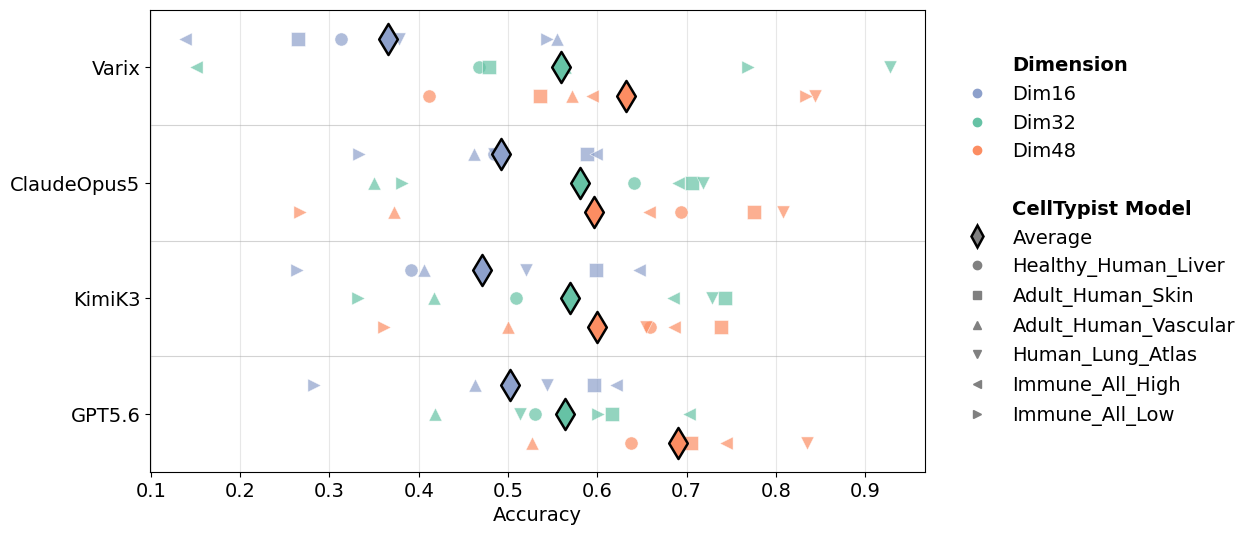

In [25]:
compact_point_plot(df_performance, "Accuracy", color_mapping)
plt.show()

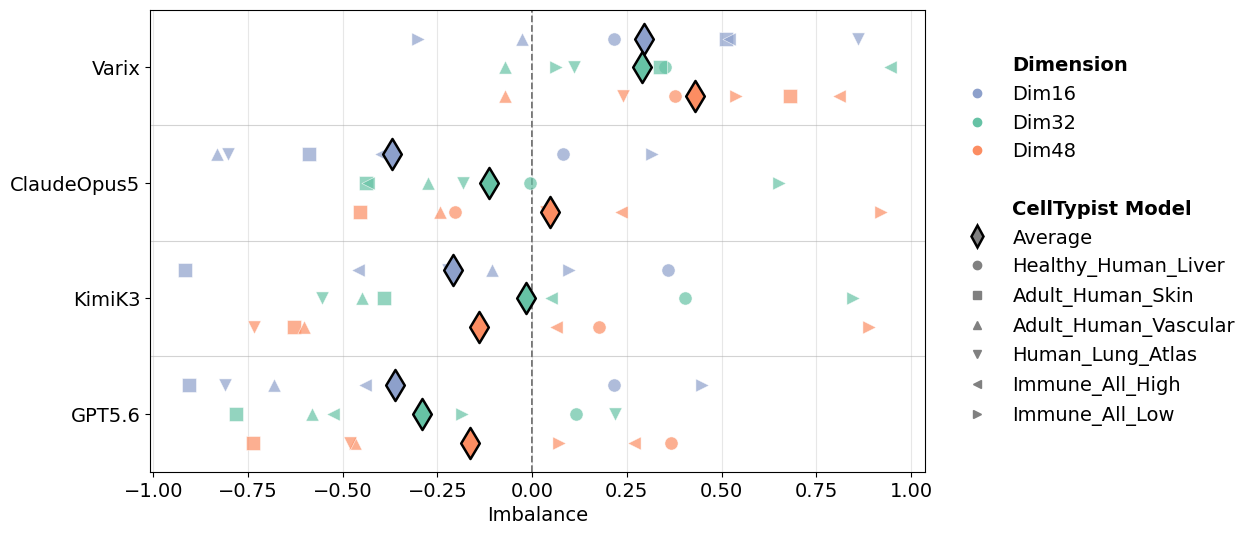

In [26]:
compact_point_plot(df_performance, "Imbalance", color_mapping, zero_line=True)
plt.show()